## Exercise 1

Compare eigenvalue decomposition and SVD

1. Generate a $4\times 4$ random matrix $A$
2. Generate a symmetric $4\times 4$ symmetric matrix by $A^TA$
3. In numpy calculate the eigen decomposition
4. In numpy calculate the SVD decomposition
5. Compare the decompositions, are they the same or essentially the same
6. Try with the matrix give below
7. Look at sign an order

$$
C =
\begin{pmatrix}
2 & 1 & 0 & 0 \\
1 & 2 & 0 & 0 \\
0 & 0 & -3 & 1 \\
0 & 0 & 1 & -3
\end{pmatrix}
$$

In [26]:
import numpy as np

A=np.random.randn(4,4)
B=A.T@A
C=np.array([[2,1,0,0],[1,2,0,0],[0,0,-3,1],[0,0,1,-3]])

eig,V=np.linalg.eig(B)

U,S,Vt=np.linalg.svd(B)

eig_c,V_c=np.linalg.eig(C)

U_c,S_c,Vt_c=np.linalg.svd(C)

print("Eigenvectors for B\n")
print(V)
print("\nSVD U for B\n")
print(U)
print("\nSVD V for B\n")
print(Vt.T)



print("\nSingular values for B")
print(S)
print("\nEigenvalues for B")
print(eig)


print("\nSingular values for C")
print(S_c)
print("Eigenvalues for C")
print(eig_c)




Eigenvectors for B

[[ 0.17015746  0.9283647  -0.31244289 -0.10754005]
 [ 0.28193261 -0.33473199 -0.88851236  0.13789229]
 [ 0.84518882  0.00517071  0.33131899  0.41935289]
 [-0.42097066  0.16145198 -0.05615117  0.8908221 ]]

SVD U for B

[[-0.17015746  0.9283647   0.10754005  0.31244289]
 [-0.28193261 -0.33473199 -0.13789229  0.88851236]
 [-0.84518882  0.00517071 -0.41935289 -0.33131899]
 [ 0.42097066  0.16145198 -0.8908221   0.05615117]]

SVD V for B

[[-0.17015746  0.9283647   0.10754005  0.31244289]
 [-0.28193261 -0.33473199 -0.13789229  0.88851236]
 [-0.84518882  0.00517071 -0.41935289 -0.33131899]
 [ 0.42097066  0.16145198 -0.8908221   0.05615117]]

Singular values for B
[11.93304458  1.16780026  0.1626818   0.08077656]

Eigenvalues for B
[11.93304458  1.16780026  0.08077656  0.1626818 ]

Singular values for C
[4. 3. 2. 1.]
Eigenvalues for C
[ 3.  1. -2. -4.]


## Exercise 2
Using the spectral theorem compute the SVD by hand for the matrix.

Some of the operations such as normalizing vectors and constructing the final matrices $U$, $V$ and $\Sigma$ you cando in numpy
$$
A =
\begin{bmatrix}
1 & 2 \\
3 & 4
\end{bmatrix}
$$

## Solution
We first calculate $A^TA$ which is symmetric and positive definite

$$
\begin{bmatrix}
1 & 3 \\
2 & 4
\end{bmatrix}
\begin{bmatrix}
1 & 2 \\
3 & 4
\end{bmatrix}
=
\begin{bmatrix}
10 & 14 \\
14 & 20
\end{bmatrix}
$$
We determine eigenvalues by the roots of the characteristic polynomial

$p(\lambda)=(10-\lambda)(20-\lambda)-14^2=0$

The roots are $\lambda=15\pm \sqrt{221} >=0$

So the singular values becomes $\sigma_i= \sqrt{15\pm \sqrt{221}}$

Now for the eigen vectors we have to solve for $S=A^TA$

$Sx=\lambda x$

that is the linear systems

$$
\begin{bmatrix}
10 & 14 \\
14 & 20
\end{bmatrix}
\begin{bmatrix}
x  \\
y
\end{bmatrix}
=\lambda_i
\begin{bmatrix}
x  \\
y
\end{bmatrix}
$$
That is
$$
\begin{bmatrix}
10-\lambda_i & 14 \\
14 & 20-\lambda_i
\end{bmatrix}
\begin{bmatrix}
x  \\
y
\end{bmatrix}
=
0
$$

We choose $x=1$ so $(10-\lambda_i)+14y=0$ implying $(1,\frac{(\lambda_i-10)}{14})$ are solutions

You can check that these are orthogonal

But they have to be normalized

Let's do that in numpy


In [35]:
import numpy as np
lamda_1=15+np.sqrt(221)
lamda_2=15-np.sqrt(221)

x_1=np.array([1,(lamda_1-10)/14])
x_2=np.array([1,(lamda_2-10)/14])

print(f'Inner {np.inner(x_1,x_2)}')

x_1=x_1/np.linalg.norm(x_1)
x_2=x_2/np.linalg.norm(x_2)

print(f'Inner {np.inner(x_1,x_2)}')

print(x_1)
print(x_2)




Inner -2.220446049250313e-16
Inner -5.551115123125783e-17
[0.57604844 0.81741556]
[ 0.81741556 -0.57604844]


## Solution
From the eigenvectors $V$ is constructed
$$
V=
\begin{bmatrix}
0.576048841 & 0.81741556  \\
0.81741556 & -0.57604844
\end{bmatrix}
$$

But now for the $u_i= \sigma_iAv_i$. Let us calculate in numpy again

In [40]:
A = np.array([[1,2],[3,4]])

# eigenvalues
lamda_1 = 15 + np.sqrt(221)
lamda_2 = 15 - np.sqrt(221)

sigma_1 = np.sqrt(lamda_1)
sigma_2 = np.sqrt(lamda_2)

# eigenvectors of A^T A
x_1 = np.array([1, (lamda_1 - 10)/14])
x_2 = np.array([1, (lamda_2 - 10)/14])

x_1 = x_1 / np.linalg.norm(x_1)
x_2 = x_2 / np.linalg.norm(x_2)

# right singular vectors
V = np.column_stack((x_1, x_2))

# left singular vectors: u_i = A v_i / sigma_i
u_1 = (A @ x_1) / sigma_1
u_2 = (A @ x_2) / sigma_2

print(np.linalg.norm(u_1))

U = np.column_stack((u_1,u_2))

S = np.diag([sigma_1, sigma_2])

A_r = U @ S @ V.T

print(A_r)

1.0
[[1. 2.]
 [3. 4.]]


## Exercise 3
Consider the array
$$
M=
\begin{bmatrix}
1& 2\\
3& 4\\
5& 6
\end{bmatrix}
$$
Compute SVD in numpy and verify reconstrúction


In [2]:
import numpy as np
M=np.array([[1,2],[3,4],[5,6]])
U,S,Vt=np.linalg.svd(M,full_matrices=False)
S_r=np.diag(S)

assert np.allclose(M,U@S_r@Vt)

## Exercise 4 intro
Consider the image

![image](data/stravin.jpg)

1. We load the image and make a subplot ready for say 2 plots
2. Next we reduce to grayscale. Remember that the plot has to bein grayscale also

(597, 463)


Text(0.5, 1.0, 'Grey Scale')

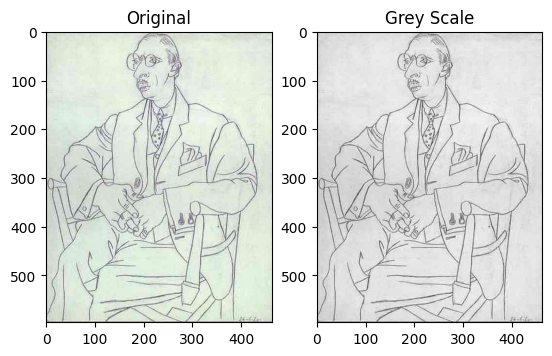

In [8]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt

img = imageio.imread("data/stravin.jpg")
gray = np.mean(img, axis=2)
print(gray.shape)
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(gray,cmap="gray")
plt.title("Grey Scale")




## Exercise 4 a)
1. Decompose the grayscale image into SVD
2. Plot the recovered image remember to round to integers in 0..255

Use
```python
def clip(image):
    return np.rint(np.clip(image, 0, 255)).astype(np.uint8)
````



(597, 463)
float64


Text(0.5, 1.0, 'Recovered')

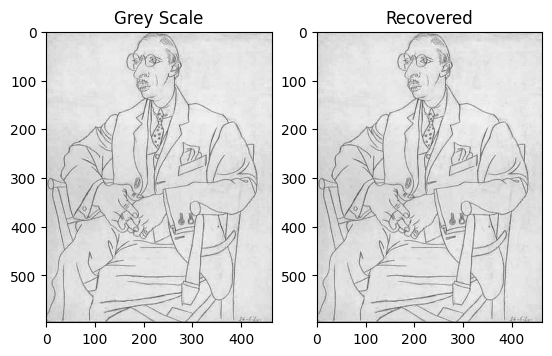

In [24]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt

def clip(image):
    return np.rint(np.clip(image, 0, 255)).astype(np.uint8)


img = imageio.imread("data/stravin.jpg")
gray = np.mean(img, axis=2)
print(gray.shape)

plt.subplot(1, 2, 1)
plt.imshow(gray,cmap="gray")
plt.title("Grey Scale")

U,S,Vt=np.linalg.svd(gray,full_matrices=False)

recovered=U@np.diag(S)@Vt

print(recovered.dtype)
plt.subplot(1, 2, 2)

plt.imshow(clip(recovered),cmap="gray")
plt.title("Recovered")







## Exercise 4 b)

Try to recover the image for all colors doing SVD in each color



Text(0.5, 1.0, 'Recovered')

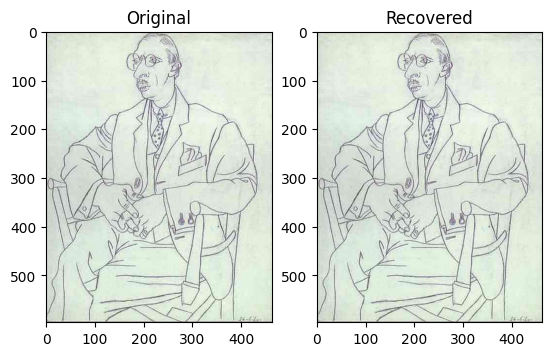

In [26]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt

def clip(image):
       return np.rint(np.clip(image, 0, 255)).astype(np.uint8)



img = imageio.imread("data/stravin.jpg")
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original")



img_r=img[:,:,0]
img_g=img[:,:,1]
img_b=img[:,:,2]

U_r,S_r,V_r=np.linalg.svd(img_r,full_matrices=False)
U_g,S_g,V_g=np.linalg.svd(img_g,full_matrices=False)
U_b,S_b,V_b=np.linalg.svd(img_b,full_matrices=False)


combined = clip(np.stack((U_r@np.diag(S_r)@V_r, U_g@np.diag(S_g)@V_g, U_b@np.diag(S_b)@V_b), axis=2))
plt.subplot(1, 2, 2)
plt.imshow(combined)
plt.title("Recovered")



## Exercise 4 c)
Now try to make reconstruction from single singular-value. From the top say and then the first 10(maybe higher) single rank approximations in grayscale

That is you reconstruct $L_1$ with only $\sigma_1$ and $L_2$ with only $\sigma_2$ and so on

In this context you might need the numpy function
```python
np.outer(x,y)
```
because when you reduce the matrices to vectors the matrix multiplication becomes inner product instead

If you slice correctly you do not need the outer function (hint: slice by $i:i+1$)

## Exercise 4 c)

After investigating the rank-1 images try to recover the image by say $k=100$ singular values from the top.

Calculate the energy retention
$$
ER=\frac{\sum_{i=1}^{k}\sigma_i^2}{\sum_{i=1}^{n}\sigma_i^2}
$$
Also calculate the compression rate defined as

$$
CR=\frac{\#\text{bytes compressed image}}{\#\text{bytes full image}}
$$

also investigate the values of $ER$ to quality


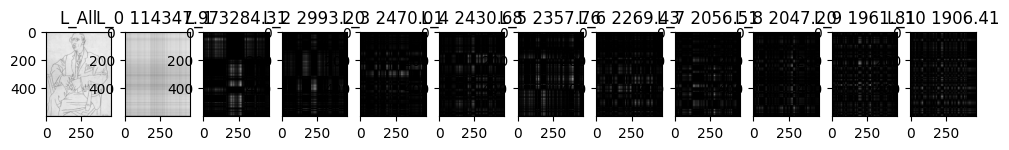

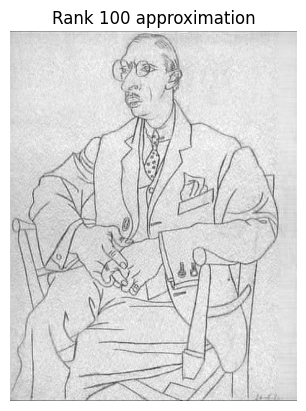

In [65]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt

def clip(image):
    return np.rint(np.clip(image, 0, 255)).astype(np.uint8)


img = imageio.imread("data/stravin.jpg")

gray = np.mean(img, axis=2)



plots=11
plt.figure(figsize=(12, 4))
plt.subplot(1, plots+1, 1)
plt.imshow(gray,cmap="gray")
plt.title("L_All")

U,S,Vt=np.linalg.svd(gray,full_matrices=False)


for i in range(plots):
    recovered = S[i] * (U[:, i:i+1] @ Vt[i:i+1, :])
    plt.subplot(1, plots+1, i+2)
    plt.imshow(clip(recovered),cmap="gray")
    plt.title(f'L_{i} {S[i]:.2f}')

# recover
rec=100
R=U[:,:rec]@np.diag(S[:rec])@Vt[:rec,:]

plt.figure()   # <-- NEW PLOT WINDOW
plt.imshow(clip(R), cmap="gray")
plt.title(f"Rank {rec} approximation")
plt.axis("off")
plt.show()



## Exercise 5
In the linear normal model we have

$$
\hat{\beta}=(D^TD)^{-1}D^Ty
$$
#### a)
Try to substitute an SVD decomposition  for the design matrix $D$ and calculate the formula for $\hat{\beta} $

It is assumed that no zero singular values are present


It should be
$$
\hat{\beta}=V\Sigma ^{-1}U^Ty
$$


#### b)
What happens if singular values are small?

If the  singular values get too small what could be done?



#### a)
$D=U\Sigma V^T$

So we have
\begin{align*}
\hat{\beta}&= ( (U\Sigma V^T)^T(U\Sigma V^T))^{-1}(U\Sigma V^T)^Ty\\
\hat{\beta}&= ( V\Sigma U^TU\Sigma V^T)^{-1}(V\Sigma U^T)y\\
\hat{\beta}&= ( V\Sigma^2V^T)^{-1}V\Sigma U^Ty\\
\hat{\beta}&=  V(\Sigma^2)^{-1}V^TV\Sigma U^Ty\\
\hat{\beta}&=  V(\Sigma^2)^{-1}\Sigma U^Ty\\
\hat{\beta}&=  V(\Sigma)^{-1}U^Ty
\end{align*}

#### b)
A possible solution is to remove (truncate) small singular values, similar to SVD-based compression. This reduces the influence of unstable directions in the data and prevents noise amplification in the estimate of $\hat{\beta}$
